# MedVision Smart — Segmentation biomédicale intelligente
## Étape 1 · Notebook 01 : Exploration, nettoyage et découpage des données

**Équipe :** Abderrahman Ghazouani · Hiba Hamrani · Anas Latifi

---

### Problématique

L'échographie mammaire est un examen essentiel pour détecter les tumeurs du sein. Délimiter précisément le contour d'une tumeur est **long à faire à la main** et **varie d'un radiologue à l'autre**.

L'objectif du projet est de **segmenter automatiquement** les tumeurs : pour chaque image, un modèle produit un **masque binaire** où chaque pixel vaut **1 (tumeur)** ou **0 (fond)**. Une plateforme permettra ensuite à un humain de **comparer, corriger et valider** ces masques.

### Jeu de données : BUSI

*Breast Ultrasound Images Dataset* (Kaggle) : 780 échographies réparties en 3 classes (**benign**, **malignant**, **normal**), accompagnées de masques tracés par des radiologues. Ces masques sont la **vérité terrain** que les modèles doivent apprendre à reproduire.

### Les 4 algorithmes comparés dans l'étape 1

| # | Algorithme | Rôle | Question posée |
|---|---|---|---|
| 1 | Seuillage d'Otsu | Baseline simple, sans apprentissage | Faut-il vraiment du deep learning ? |
| 2 | CNN encodeur-décodeur simple | Modèle classique, sans skip connections | L'apprentissage seul suffit-il ? |
| 3 | U-Net | Modèle de référence (énoncé) | Les skip connections aident-elles ? |
| 4 | U-Net++ | Architecture avancée imposée | Les skip connections denses valent-elles leur coût ? |

### Organisation des notebooks

| Notebook | Contenu |
|---|---|
| **01_exploration** (ce notebook) | Exploration, nettoyage, découpage train/val/test → `splits.csv` |
| 02_baselines | Otsu + CNN simple, fonctions de métriques |
| 03_unet_unetpp | U-Net, U-Net++, réglage des hyperparamètres (GPU) |
| 04_evaluation | Évaluation finale sur le test, tableau comparatif, analyse d'erreurs |

### Plan de ce notebook

0. Préparation de l'environnement
1. Exploration des données
2. Nettoyage
3. Découpage train / validation / test
4. Fonctions partagées (`utils.py`)
5. Synthèse

---
## 0. Préparation de l'environnement

### Les bibliothèques utilisées

| Bibliothèque | Rôle dans ce notebook |
|---|---|
| `os`, `glob` | Parcourir les dossiers et trouver les fichiers |
| `hashlib` | Calculer une « empreinte » de chaque image pour détecter les doublons |
| `numpy` | Manipuler les images comme des tableaux de nombres |
| `pandas` | Ranger les informations sur chaque image dans un tableau (DataFrame) |
| `cv2` (OpenCV) | Lire les images et les masques |
| `matplotlib`, `seaborn` | Tracer les graphiques |
| `sklearn` | Faire le découpage train / validation / test stratifié |

### Pourquoi fixer une « seed » ?

Plusieurs opérations utilisent le hasard (choisir des exemples à afficher, mélanger les données avant le découpage). En fixant la **seed** (graine aléatoire) à 42, le hasard devient **reproductible** : si on relance le notebook, on obtient **exactement les mêmes résultats**. C'est une exigence du prof (*pipeline reproductible*).

### Les chemins

- `DATA_DIR` : là où se trouve le dataset BUSI dézippé.
- `OUT_DIR` : un dossier `outputs` où on enregistre les figures (pour le rapport) et les fichiers produits.

⚠️ Le notebook doit être lancé **depuis le dossier `medvision-smart`**, sinon le chemin `data/...` ne sera pas trouvé. La dernière ligne de la cellule vérifie justement que le dossier existe : elle doit afficher `True`.

In [1]:
# --- Bibliothèques ---
import os
import glob
import hashlib
import random

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# --- Reproductibilité ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Chemins ---
DATA_DIR = "data/Dataset_BUSI_with_GT"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# --- Constantes ---
CLASSES = ["benign", "malignant", "normal"]
COULEURS = {"benign": "#4C72B0", "malignant": "#C44E52", "normal": "#55A868"}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)

print("Dossier du dataset trouvé :", os.path.isdir(DATA_DIR))

Dossier du dataset trouvé : True


---
## 1. Exploration des données

Avant de toucher aux modèles, il faut **connaître ses données** : combien d'images, dans quelles classes, de quelle taille, à quoi ressemblent les tumeurs. Chaque observation de cette partie justifie une décision prise plus tard (stratification, redimensionnement, analyse des petites tumeurs…).

### 1.1 Inventaire des fichiers

Dans chaque dossier de classe, les fichiers sont nommés ainsi :

| Fichier | Contenu |
|---|---|
| `benign (1).png` | l'échographie |
| `benign (1)_mask.png` | le masque de la tumeur |
| `benign (1)_mask_1.png` | un **deuxième** masque, s'il y a une deuxième lésion |

Le code ci-dessous parcourt les 3 dossiers et construit un tableau avec **une ligne par échographie** :

- `id` : le nom de l'image, sans `.png` (ex. `benign (1)`) ;
- `classe` : benign, malignant ou normal ;
- `image_path` : le chemin de l'image ;
- `mask_paths` : le ou les chemins des masques, séparés par `;` ;
- `nb_masques` : le nombre de masques trouvés.

Les fichiers contenant `_mask` sont ignorés dans la boucle principale, puisque ce ne sont pas des échographies. `replace("\\", "/")` uniformise les chemins Windows pour que le fichier final marche sur tous les PC du groupe.

In [2]:
rows = []
for classe in CLASSES:
    for img_path in sorted(glob.glob(os.path.join(DATA_DIR, classe, "*.png"))):
        if "_mask" in os.path.basename(img_path):
            continue  # on ignore les fichiers masques
        base = img_path[:-4]  # chemin sans ".png"
        masks = sorted(glob.glob(base + "_mask*.png"))
        rows.append({
            "id": os.path.basename(base),
            "classe": classe,
            "image_path": img_path.replace("\\", "/"),
            "mask_paths": ";".join(m.replace("\\", "/") for m in masks),
            "nb_masques": len(masks),
        })

df = pd.DataFrame(rows)
print("Nombre total d'échographies :", len(df))
df.head()

Nombre total d'échographies : 780


,id,classe,image_path,mask_paths,nb_masques
0,benign (1),benign,data/Dataset_BUSI_with_GT/benign/benign (1).png,data/Dataset_BUSI_with_GT/benign/benign (1)_mask.png,1
1,benign (10),benign,data/Dataset_BUSI_with_GT/benign/benign (10).png,data/Dataset_BUSI_with_GT/benign/benign (10)_mask.png,1
2,benign (100),benign,data/Dataset_BUSI_with_GT/benign/benign (100).png,data/Dataset_BUSI_with_GT/benign/benign (100)_mask.png;d...,2
3,benign (101),benign,data/Dataset_BUSI_with_GT/benign/benign (101).png,data/Dataset_BUSI_with_GT/benign/benign (101)_mask.png,1
4,benign (102),benign,data/Dataset_BUSI_with_GT/benign/benign (102).png,data/Dataset_BUSI_with_GT/benign/benign (102)_mask.png,1


### 1.2 Répartition des classes

On compte le nombre d'images par classe et leur pourcentage. C'est important car si une classe est **beaucoup plus rare**, elle risque d'être **mal représentée** dans le jeu de test si on découpe au hasard.

,nb_images,pourcentage (%)
classe,,
benign,437,56.0
malignant,210,26.9
normal,133,17.1


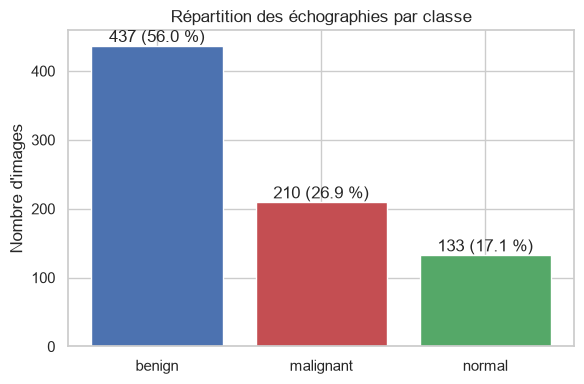

In [3]:
repartition = df["classe"].value_counts().reindex(CLASSES)
pourcentage = (repartition / len(df) * 100).round(1)
display(pd.DataFrame({"nb_images": repartition, "pourcentage (%)": pourcentage}))

fig, ax = plt.subplots(figsize=(6, 4))
barres = ax.bar(repartition.index, repartition.values,
                color=[COULEURS[c] for c in repartition.index])
ax.bar_label(barres, labels=[f"{n} ({p} %)" for n, p in zip(repartition, pourcentage)])
ax.set_title("Répartition des échographies par classe")
ax.set_ylabel("Nombre d'images")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/repartition_classes.png", dpi=150)
plt.show()

### 1.3 Nombre de masques par image

Normalement, une image = un masque. Mais quand une échographie contient **plusieurs lésions**, BUSI fournit **un fichier masque par lésion**. On compte ces cas, puis on affiche la liste des images concernées.

In [4]:
display(df["nb_masques"].value_counts().sort_index().rename("nb_images").to_frame())

multi = df[df["nb_masques"] > 1]
print(f"{len(multi)} images ont plusieurs masques :")
display(multi[["id", "classe", "nb_masques"]])

,nb_images
nb_masques,
1,763
2,16
3,1


17 images ont plusieurs masques :


,id,classe,nb_masques
2,benign (100),benign,2
71,benign (163),benign,2
82,benign (173),benign,2
91,benign (181),benign,2
106,benign (195),benign,3
167,benign (25),benign,2
240,benign (315),benign,2
274,benign (346),benign,2
333,benign (4),benign,2
361,benign (424),benign,2


**Observations :**

- **780 images** : 437 benign (56 %), 210 malignant (27 %), 133 normal (17 %).
  → Les classes sont **déséquilibrées** : il y a deux fois plus d'images bénignes que malignes. Le découpage devra être **stratifié par classe**, pour que train, validation et test gardent les mêmes proportions.
- **17 images ont plusieurs masques** (16 avec 2 masques, 1 avec 3), car elles contiennent plusieurs lésions.
  → Un modèle attend **un seul masque par image** : ils seront **fusionnés** au nettoyage.
- Les images **normal** n'ont pas de tumeur : leur masque doit être **entièrement noir**. On le vérifiera.

### 1.4 Visualisation d'exemples

On définit d'abord deux fonctions qu'on réutilisera partout :

- **`lire_image(chemin)`** : lit l'échographie en **niveaux de gris** (`IMREAD_GRAYSCALE`). Les fichiers BUSI sont enregistrés en couleur, mais l'échographie est en noir et blanc : un seul canal suffit.
- **`lire_masque(mask_paths)`** : lit **tous** les masques d'une image et les **fusionne** :
  - `> 0` transforme chaque masque en vrai/faux (pixel de tumeur ou non) ;
  - `|` est le **OU logique** : un pixel est « tumeur » s'il l'est **dans au moins un** des masques ;
  - le résultat est converti en `uint8` avec des valeurs **0 ou 1**.

Ensuite on affiche, pour un exemple tiré au hasard dans chaque classe : l'image, son masque, et le masque **superposé en rouge** sur l'image (`alpha=0.4` = transparence), pour vérifier que le contour tombe bien sur la tumeur.

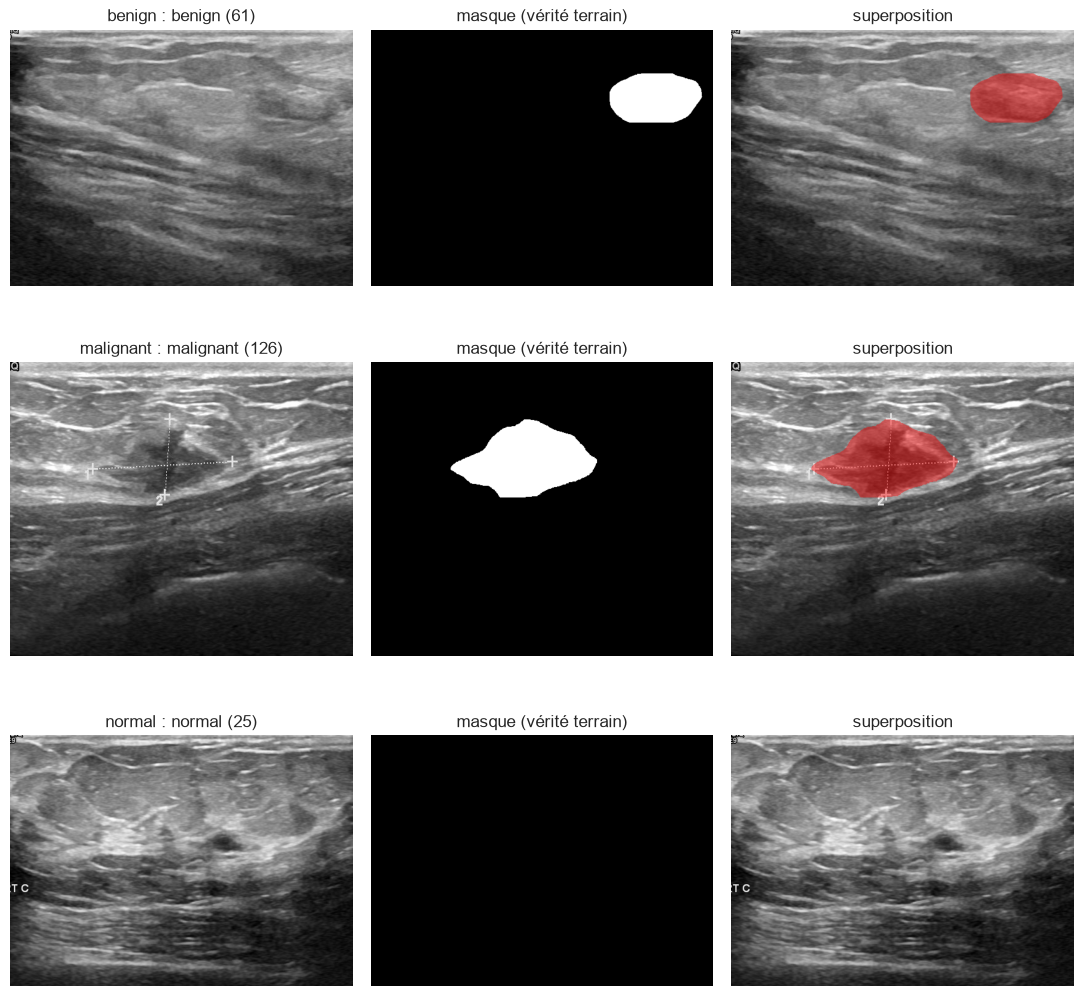

In [5]:
def lire_image(chemin):
    # Lit une échographie en niveaux de gris (tableau 2D de valeurs 0-255).
    return cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)


def lire_masque(mask_paths):
    # Lit et fusionne (OU logique) tous les masques d'une image. Renvoie un tableau 0/1.
    masque = None
    for chemin in mask_paths.split(";"):
        m = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) > 0
        masque = m if masque is None else (masque | m)
    return masque.astype(np.uint8)


fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for i, classe in enumerate(CLASSES):
    exemple = df[df["classe"] == classe].sample(1, random_state=SEED).iloc[0]
    img = lire_image(exemple["image_path"])
    masque = lire_masque(exemple["mask_paths"])

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"{classe} : {exemple['id']}")
    axes[i, 1].imshow(masque, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("masque (vérité terrain)")
    axes[i, 2].imshow(img, cmap="gray")
    axes[i, 2].imshow(np.ma.masked_where(masque == 0, masque), cmap="autumn", alpha=0.45)
    axes[i, 2].set_title("superposition")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/exemples_par_classe.png", dpi=150)
plt.show()

**Ce qu'on remarque en général sur BUSI :**

- Les tumeurs apparaissent comme des **zones sombres** (hypoéchogènes).
- Les tumeurs **bénignes** ont souvent un contour **rond et régulier** ; les **malignes** un contour plus **irrégulier**, parfois flou.
- L'image contient beaucoup de **bruit** (le « grain » typique de l'échographie) et parfois des **annotations** de l'appareil sur les bords.
- D'autres zones sombres qui **ne sont pas des tumeurs** existent : c'est ce qui va piéger la baseline d'Otsu, qui ne fait que séparer le sombre du clair.

### 1.5 Analyse de chaque image

On parcourt maintenant **toutes** les images une seule fois, et pour chacune on calcule :

| Colonne | Signification | Pourquoi c'est utile |
|---|---|---|
| `hauteur`, `largeur` | Taille de l'image en pixels | Décider de la taille de redimensionnement |
| `taille_ok` | L'image et son masque ont-ils la même taille ? | Détecter des fichiers incohérents |
| `ratio_tumeur` | Part de l'image occupée par la tumeur (moyenne du masque) | Repérer les petites tumeurs, difficiles à segmenter |
| `nb_lesions` | Nombre de zones blanches séparées dans le masque fusionné | Vérifier les images à plusieurs lésions |
| `hash` | Empreinte MD5 des pixels de l'image | Détecter les **doublons** (même image = même empreinte) |

`cv2.connectedComponents` compte les « îlots » de pixels blancs ; on enlève 1 car il compte aussi le fond. `tqdm` affiche une barre de progression.

In [6]:
infos = []
for _, ligne in tqdm(df.iterrows(), total=len(df), desc="Analyse des images"):
    img = lire_image(ligne["image_path"])
    masque = lire_masque(ligne["mask_paths"])
    infos.append({
        "hauteur": img.shape[0],
        "largeur": img.shape[1],
        "taille_ok": img.shape == masque.shape,
        "ratio_tumeur": float(masque.mean()),
        "nb_lesions": cv2.connectedComponents(masque)[0] - 1,
        "hash": hashlib.md5(str(img.shape).encode() + img.tobytes()).hexdigest(),
    })

df = pd.concat([df, pd.DataFrame(infos)], axis=1)
df.head()

Analyse des images: 100%|██████████| 780/780 [00:26<00:00, 29.93it/s]


,id,classe,image_path,mask_paths,nb_masques,hauteur,largeur,taille_ok,ratio_tumeur,nb_lesions,hash
0,benign (1),benign,data/Dataset_BUSI_with_GT/benign/benign (1).png,data/Dataset_BUSI_with_GT/benign/benign (1)_mask.png,1,471,562,True,0.003717,1,30110d92f6ee8768f3eeb3a3cafbce85
1,benign (10),benign,data/Dataset_BUSI_with_GT/benign/benign (10).png,data/Dataset_BUSI_with_GT/benign/benign (10)_mask.png,1,585,683,True,0.082387,1,515d4fde4762756f496d7958cc179ee0
2,benign (100),benign,data/Dataset_BUSI_with_GT/benign/benign (100).png,data/Dataset_BUSI_with_GT/benign/benign (100)_mask.png;d...,2,473,323,True,0.065526,2,4d97962935ecb4d50628a7711e177228
3,benign (101),benign,data/Dataset_BUSI_with_GT/benign/benign (101).png,data/Dataset_BUSI_with_GT/benign/benign (101)_mask.png,1,473,563,True,0.015648,1,1802770b76fd8105e5c736436fb95001
4,benign (102),benign,data/Dataset_BUSI_with_GT/benign/benign (102).png,data/Dataset_BUSI_with_GT/benign/benign (102)_mask.png,1,610,634,True,0.048759,1,8c16246073bbd3303f6a76415c18f0b3


### 1.6 Taille des images

Un réseau de neurones attend des images **toutes de la même taille**. On regarde donc si les tailles varient.

,hauteur,largeur
count,780.0,780.0
mean,501.0,616.0
std,77.0,122.0
min,310.0,190.0
25%,465.0,554.0
50%,474.0,564.0
75%,574.0,714.0
max,719.0,1048.0


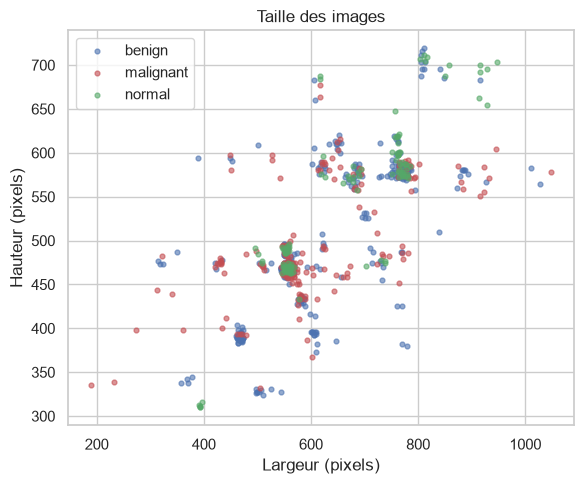

Images dont le masque n'a pas la même taille : 0


In [7]:
display(df[["hauteur", "largeur"]].describe().round(0))

fig, ax = plt.subplots(figsize=(6, 5))
for classe in CLASSES:
    sous = df[df["classe"] == classe]
    ax.scatter(sous["largeur"], sous["hauteur"], s=12, alpha=0.6,
               label=classe, color=COULEURS[classe])
ax.set_xlabel("Largeur (pixels)")
ax.set_ylabel("Hauteur (pixels)")
ax.set_title("Taille des images")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/tailles_images.png", dpi=150)
plt.show()

print("Images dont le masque n'a pas la même taille :", (~df["taille_ok"]).sum())

**Interprétation :** les images n'ont **pas toutes la même taille** (en moyenne autour de 500 × 600 pixels sur BUSI). Il faudra donc les **redimensionner** à une taille fixe avant l'entraînement. L'énoncé demande **128 à 256 px** : on testera **128 et 256** comme hyperparamètre.

- 128 px : entraînement **plus rapide**, mais les **petits détails** du contour sont perdus.
- 256 px : contours plus **précis**, mais **4 fois plus de pixels** à traiter.

On vérifie aussi que chaque masque a **exactement la taille de son image**, sinon la superposition pixel par pixel n'aurait pas de sens.

### 1.7 Taille des tumeurs

`ratio_tumeur` indique quelle **part de l'image** est occupée par la tumeur. Par exemple, 0,05 = 5 % de l'image. On compare les classes benign et malignant (les images normal valent 0, sans tumeur).

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
benign,437.0,6.88,8.34,0.28,1.51,3.79,9.13,51.30
malignant,210.0,14.74,10.71,0.51,6.05,12.06,20.66,56.29


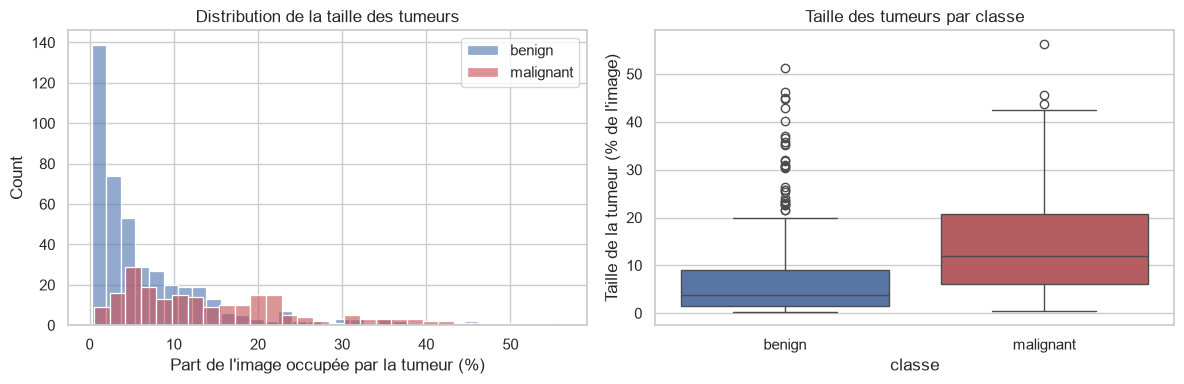

Tumeurs occupant moins de 1 % de l'image : 61 (9.4 % des images avec tumeur)


In [8]:
tumeurs = df[df["classe"] != "normal"].copy()
tumeurs["ratio_tumeur_%"] = tumeurs["ratio_tumeur"] * 100

display(tumeurs.groupby("classe")["ratio_tumeur_%"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for classe in ["benign", "malignant"]:
    sns.histplot(tumeurs[tumeurs["classe"] == classe]["ratio_tumeur_%"], bins=30,
                 ax=axes[0], color=COULEURS[classe], label=classe, alpha=0.6)
axes[0].set_xlabel("Part de l'image occupée par la tumeur (%)")
axes[0].set_title("Distribution de la taille des tumeurs")
axes[0].legend()

sns.boxplot(data=tumeurs, x="classe", y="ratio_tumeur_%", ax=axes[1],
            hue="classe", palette=COULEURS, legend=False)
axes[1].set_ylabel("Taille de la tumeur (% de l'image)")
axes[1].set_title("Taille des tumeurs par classe")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/taille_tumeurs.png", dpi=150)
plt.show()

petites = (tumeurs["ratio_tumeur_%"] < 1).sum()
print(f"Tumeurs occupant moins de 1 % de l'image : {petites} "
      f"({petites / len(tumeurs) * 100:.1f} % des images avec tumeur)")

**Interprétation :**

- La taille des tumeurs **varie énormément** : certaines occupent une grande partie de l'image, d'autres **moins de 1 %**.
- Les **petites tumeurs** sont les plus difficiles : quelques pixels d'erreur suffisent à faire chuter le Dice. Elles seront un **cas à part dans l'analyse d'erreurs** (notebook 04).
- Le **déséquilibre pixel** est fort : même dans une image avec tumeur, la grande majorité des pixels sont du **fond**. C'est pour ça qu'on teste une perte **Dice** (qui regarde la forme globale de la tumeur) en plus de la **BCE** (qui juge chaque pixel et peut être « dominée » par le fond).

---
## 2. Nettoyage

Le nettoyage corrige les problèmes trouvés à l'exploration **avant** le découpage. Ordre important : si on découpait d'abord, deux copies d'une même image pourraient se retrouver l'une dans le train et l'autre dans le test, ce qui serait une **fuite de données**.

### 2.1 Fusion des masques multiples

La fonction `lire_masque` fusionne déjà les masques. On le vérifie visuellement sur quelques images concernées : chaque masque séparé, puis le masque fusionné. On compare aussi `nb_masques` (nombre de fichiers) et `nb_lesions` (nombre de zones dans le masque fusionné) : ils peuvent différer si deux lésions se touchent.

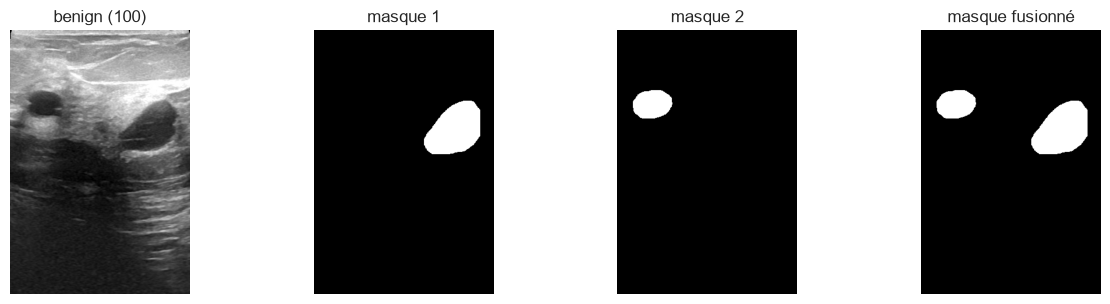

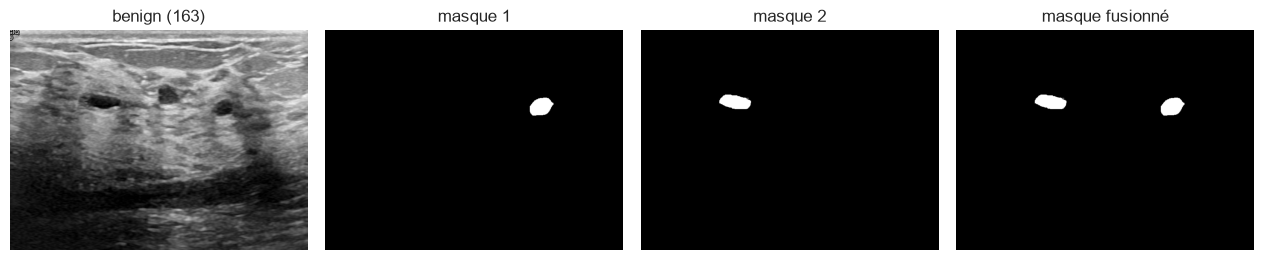

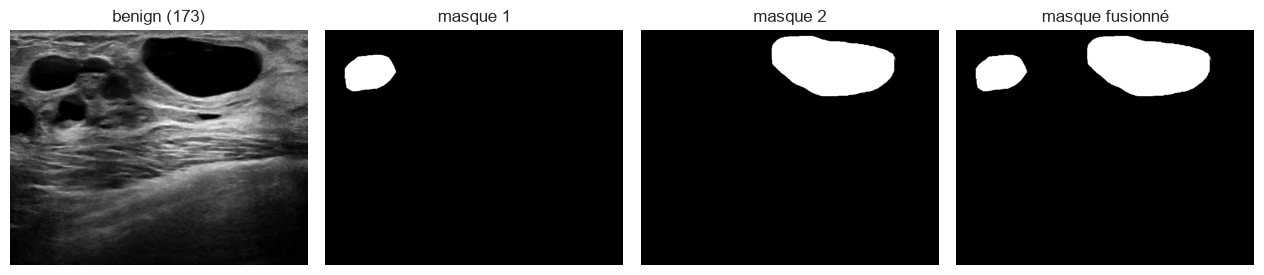

,id,classe,nb_masques,nb_lesions
2,benign (100),benign,2,2
71,benign (163),benign,2,2
82,benign (173),benign,2,2
91,benign (181),benign,2,1
106,benign (195),benign,3,2
167,benign (25),benign,2,2
240,benign (315),benign,2,2
274,benign (346),benign,2,2
333,benign (4),benign,2,2
361,benign (424),benign,2,2


In [9]:
exemples_multi = df[df["nb_masques"] > 1].head(3)

for _, ligne in exemples_multi.iterrows():
    chemins = ligne["mask_paths"].split(";")
    n = len(chemins)
    fig, axes = plt.subplots(1, n + 2, figsize=(3.2 * (n + 2), 3.2))
    axes[0].imshow(lire_image(ligne["image_path"]), cmap="gray")
    axes[0].set_title(ligne["id"])
    for k, chemin in enumerate(chemins):
        axes[k + 1].imshow(cv2.imread(chemin, cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[k + 1].set_title(f"masque {k + 1}")
    axes[-1].imshow(lire_masque(ligne["mask_paths"]), cmap="gray")
    axes[-1].set_title("masque fusionné")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

display(df[df["nb_masques"] > 1][["id", "classe", "nb_masques", "nb_lesions"]])

### 2.2 Cohérence des masques avec les classes

Deux règles doivent être respectées :

1. Une image **normal** doit avoir un masque **vide** (`ratio_tumeur = 0`).
2. Une image **benign** ou **malignant** doit avoir un masque **non vide** (`ratio_tumeur > 0`).

Les images qui ne respectent pas ces règles sont des **anomalies d'annotation** : on les affiche pour décider quoi en faire.

In [10]:
normal_non_vide = df[(df["classe"] == "normal") & (df["ratio_tumeur"] > 0)]
tumeur_vide = df[(df["classe"] != "normal") & (df["ratio_tumeur"] == 0)]

print("Images 'normal' avec un masque non vide :", len(normal_non_vide))
print("Images 'benign/malignant' avec un masque vide :", len(tumeur_vide))

anomalies = pd.concat([normal_non_vide, tumeur_vide])
if len(anomalies) > 0:
    display(anomalies[["id", "classe", "ratio_tumeur"]])

Images 'normal' avec un masque non vide : 0
Images 'benign/malignant' avec un masque vide : 0


### 2.3 Détection des doublons

BUSI contient quelques **images en double** (la même échographie enregistrée deux fois). C'est dangereux : si une copie est dans le **train** et l'autre dans le **test**, le modèle sera testé sur une image qu'il a **déjà vue**, et ses résultats seront **trop optimistes**. C'est une **fuite de données**.

**Méthode :** deux images identiques au pixel près ont la même empreinte `hash`. On regroupe les images par empreinte.

**Règle de nettoyage :**

- doublons **dans la même classe** → on garde **une seule copie** ;
- même image dans **deux classes différentes** → l'étiquette est **contradictoire**, on **retire toutes les copies**.

In [11]:
groupes = df.groupby("hash")
doublons = df[df["hash"].isin([h for h, g in groupes if len(g) > 1])].sort_values("hash")

print("Images faisant partie d'un groupe de doublons :", len(doublons))
print("Nombre de groupes de doublons :", doublons["hash"].nunique())
if len(doublons) > 0:
    display(doublons[["id", "classe", "hash"]])

Images faisant partie d'un groupe de doublons : 2
Nombre de groupes de doublons : 1


,id,classe,hash
371,benign (433),benign,8b2e92cd4bf81b6885e30115ef400d26
488,malignant (145),malignant,8b2e92cd4bf81b6885e30115ef400d26


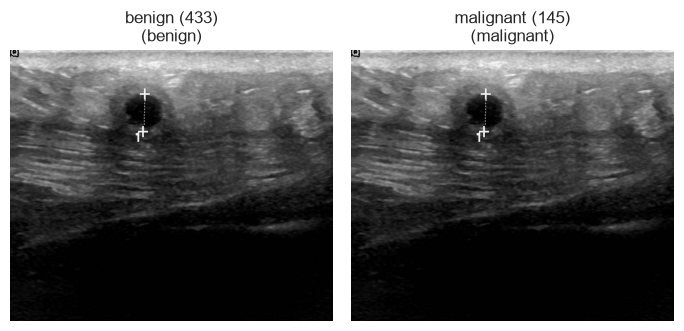

In [12]:
# Affiche les premiers groupes de doublons côte à côte pour vérifier à l'œil
for h, groupe in list(doublons.groupby("hash"))[:3]:
    fig, axes = plt.subplots(1, len(groupe), figsize=(3.5 * len(groupe), 3.5))
    axes = np.atleast_1d(axes)
    for ax, (_, ligne) in zip(axes, groupe.iterrows()):
        ax.imshow(lire_image(ligne["image_path"]), cmap="gray")
        ax.set_title(f"{ligne['id']}\n({ligne['classe']})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 2.4 Application du nettoyage

On construit le dataset propre `df_clean` :

1. on retire les **anomalies** trouvées en 2.2 (s'il y en a) ;
2. on retire les images présentes dans **plusieurs classes** ;
3. pour les autres doublons, on garde **la première copie** (`drop_duplicates`).

On affiche ensuite le **bilan** : combien d'images ont été retirées et la nouvelle répartition des classes. Ces chiffres iront dans le rapport.

In [13]:
# 1. Hash présents dans plusieurs classes différentes -> étiquette contradictoire
hash_conflit = df.groupby("hash")["classe"].nunique()
hash_conflit = hash_conflit[hash_conflit > 1].index

df_clean = df[~df.index.isin(anomalies.index)]                      # 1. anomalies
df_clean = df_clean[~df_clean["hash"].isin(hash_conflit)]           # 2. conflits
df_clean = df_clean.drop_duplicates(subset="hash", keep="first")    # 3. doublons
df_clean = df_clean.reset_index(drop=True)

bilan = pd.DataFrame({
    "avant": df["classe"].value_counts().reindex(CLASSES),
    "après": df_clean["classe"].value_counts().reindex(CLASSES),
})
bilan["retirées"] = bilan["avant"] - bilan["après"]
bilan.loc["TOTAL"] = bilan.sum()
display(bilan)

print(f"Images retirées pour conflit de classe : {df['hash'].isin(hash_conflit).sum()}")
print(f"Dataset propre : {len(df_clean)} images")

,avant,après,retirées
classe,,,
benign,437,436,1
malignant,210,209,1
normal,133,133,0
TOTAL,780,778,2


Images retirées pour conflit de classe : 2
Dataset propre : 778 images


**Bilan du nettoyage :**
- 1 paire de doublons détectée : la même échographie était présente à la fois dans *benign* et dans *malignant*.
- L'étiquette étant contradictoire, **les deux copies ont été retirées**.
- Aucune anomalie de masque (masques vides ou non vides incohérents avec la classe).
- **Dataset final : 778 images** (436 benign, 209 malignant, 133 normal).

---
## 3. Découpage train / validation / test

### Le rôle de chaque partition

| Partition | Part | Rôle |
|---|---|---|
| **Train** | 70 % | Le modèle **apprend** sur ces images |
| **Validation** | 15 % | On **choisit les hyperparamètres** (perte, learning rate, taille) en comparant les scores sur ces images |
| **Test** | 15 % | On mesure la **performance finale**, **une seule fois**, à la toute fin |

**Pourquoi trois partitions et pas deux ?** Si on choisissait les hyperparamètres en regardant le test, on « optimiserait » le modèle pour ces images précises : le score final serait trop optimiste. Le test doit rester **jamais vu** jusqu'à la fin.

### Comment on découpe

`train_test_split` est utilisé **deux fois** :

1. on sépare **70 % (train)** et **30 % (reste)** ;
2. on coupe le reste **en deux** : 15 % validation et 15 % test.

`stratify=...["classe"]` garantit que chaque partition garde **les mêmes proportions** de benign / malignant / normal. `random_state=SEED` rend le découpage **reproductible**.

### Pourquoi « par image » et pas « par patient » ?

L'énoncé demande un split **par patient** quand c'est possible, pour qu'un même patient ne soit jamais à la fois dans le train et le test. Or **BUSI ne fournit pas d'identifiant patient**. Nous faisons donc un split **par image, après suppression des doublons**, ce qui supprime la fuite la plus directe. Il reste possible que deux images *différentes* d'une même patiente soient dans des partitions différentes : c'est une **limite à mentionner dans le rapport**.

In [14]:
train_df, reste_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["classe"], random_state=SEED)
val_df, test_df = train_test_split(
    reste_df, test_size=0.50, stratify=reste_df["classe"], random_state=SEED)

df_clean["split"] = ""
df_clean.loc[train_df.index, "split"] = "train"
df_clean.loc[val_df.index, "split"] = "val"
df_clean.loc[test_df.index, "split"] = "test"

ordre = ["train", "val", "test"]
comptes = pd.crosstab(df_clean["classe"], df_clean["split"])[ordre]
comptes.loc["TOTAL"] = comptes.sum()
display(comptes)

proportions = (pd.crosstab(df_clean["classe"], df_clean["split"], normalize="columns")[ordre] * 100).round(1)
print("Proportion de chaque classe dans chaque partition (%) :")
display(proportions)

split,train,val,test
classe,,,
benign,305,65,66
malignant,146,32,31
normal,93,20,20
TOTAL,544,117,117


Proportion de chaque classe dans chaque partition (%) :


split,train,val,test
classe,,,
benign,56.1,55.6,56.4
malignant,26.8,27.4,26.5
normal,17.1,17.1,17.1


**Bilan du découpage :**
- Train : 544 images (70 %) · Validation : 117 (15 %) · Test : 117 (15 %).
- La stratification fonctionne : chaque partition garde environ 56 % benign, 27 % malignant et 17 % normal.
- Limite : le test ne compte que 31 images malignes ; les résultats par classe sont donc à interpréter avec prudence.

### Vérification visuelle et contrôles anti-fuite

Le graphique doit montrer des barres de **même forme** dans les trois partitions : c'est la preuve que la stratification a fonctionné.

Les `assert` vérifient automatiquement deux règles. Si une règle n'est pas respectée, le notebook **s'arrête avec une erreur** :

1. aucune image n'apparaît dans deux partitions ;
2. aucune empreinte (`hash`) n'est partagée entre deux partitions : donc **aucun doublon** n'est à cheval entre train et test.

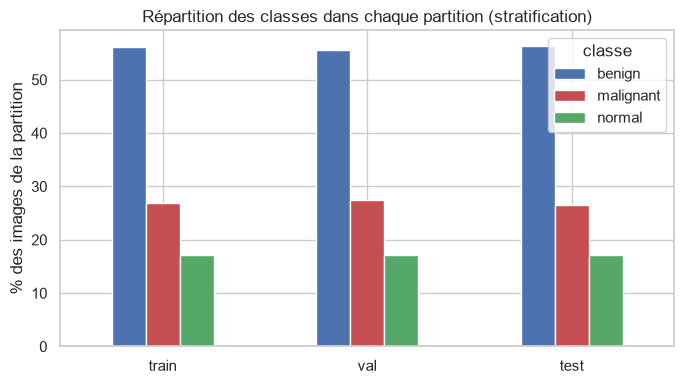

✅ Aucune fuite : aucune image ni aucun doublon partagé entre les partitions.


In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
proportions.T.plot(kind="bar", ax=ax, color=[COULEURS[c] for c in proportions.index])
ax.set_ylabel("% des images de la partition")
ax.set_xlabel("")
ax.set_title("Répartition des classes dans chaque partition (stratification)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="classe")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/stratification_split.png", dpi=150)
plt.show()

# --- Contrôles anti-fuite ---
ids = {s: set(df_clean.loc[df_clean["split"] == s, "id"] + "|" + df_clean.loc[df_clean["split"] == s, "classe"]) for s in ordre}
hashes = {s: set(df_clean.loc[df_clean["split"] == s, "hash"]) for s in ordre}

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (ids[a] & ids[b]), f"Image commune entre {a} et {b} !"
    assert not (hashes[a] & hashes[b]), f"Doublon à cheval entre {a} et {b} !"

print("✅ Aucune fuite : aucune image ni aucun doublon partagé entre les partitions.")

### Sauvegarde de `splits.csv`

C'est **le fichier le plus important de l'étape 1**. Il contient, pour chaque image, sa partition (`train`, `val` ou `test`). On le met sur GitHub, et **tous les autres notebooks le lisent** au lieu de refaire un découpage. C'est ce qui garantit que les **4 algorithmes sont comparés sur exactement les mêmes images**.

⚠️ **Règle du groupe : on ne relance jamais ce découpage** une fois `splits.csv` partagé.

On garde dans le fichier les colonnes utiles pour la suite (chemins, classe, taille de la tumeur pour l'analyse d'erreurs).

In [16]:
colonnes = ["id", "classe", "split", "image_path", "mask_paths",
            "nb_masques", "hauteur", "largeur", "ratio_tumeur", "hash"]
df_clean[colonnes].to_csv("splits.csv", index=False)

print("splits.csv enregistré :", len(df_clean), "images")
display(df_clean["split"].value_counts().reindex(ordre).rename("nb_images").to_frame())

splits.csv enregistré : 778 images


,nb_images
split,
train,544
val,117
test,117


---
## 4. Fonctions partagées : `utils.py`

Pour que **tout le groupe** lise les images et les masques **exactement de la même façon**, on regroupe les fonctions communes dans un fichier `utils.py`. La commande magique `%%writefile` écrit le contenu de la cellule dans ce fichier au lieu de l'exécuter.

Dans les notebooks suivants, il suffira d'écrire :

```python
from utils import lire_image, lire_masque, charger_split
train = charger_split("train")
```

Les fonctions de **métriques** (Dice, IoU, mAP…) seront ajoutées à ce fichier dans le notebook 02.

In [17]:
%%writefile utils.py
# Fonctions partagées du projet MedVision Smart.
import cv2
import numpy as np
import pandas as pd

SEED = 42
SPLITS_CSV = "splits.csv"


def lire_image(chemin):
    # Lit une échographie en niveaux de gris (tableau 2D, valeurs 0-255).
    return cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)


def lire_masque(mask_paths):
    # Lit et fusionne (OU logique) tous les masques d'une image. Renvoie un tableau 0/1.
    masque = None
    for chemin in mask_paths.split(";"):
        m = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) > 0
        masque = m if masque is None else (masque | m)
    return masque.astype(np.uint8)


def charger_split(split=None, chemin=SPLITS_CSV):
    # Charge splits.csv ; si split = "train", "val" ou "test", ne garde que cette partition.
    df = pd.read_csv(chemin)
    if split is not None:
        df = df[df["split"] == split].reset_index(drop=True)
    return df

Writing utils.py


**Test rapide :** on importe `utils.py` comme le feront les autres notebooks, et on vérifie que le chargement de chaque partition fonctionne.

In [18]:
import importlib
import utils
importlib.reload(utils)

for s in ["train", "val", "test"]:
    part = utils.charger_split(s)
    print(f"{s:5s} : {len(part)} images")

exemple = utils.charger_split("train").iloc[0]
m = utils.lire_masque(exemple["mask_paths"])
print("Exemple :", exemple["id"], "| masque :", m.shape, "| valeurs :", np.unique(m))

train : 544 images
val   : 117 images
test  : 117 images
Exemple : benign (1) | masque : (471, 562) | valeurs : [0 1]


---
## 5. Synthèse

### Ce que l'exploration nous a appris

| Constat | Décision prise |
|---|---|
| 780 images, classes déséquilibrées (56 / 27 / 17 %) | Découpage **stratifié** par classe |
| 17 images ont plusieurs masques | Masques **fusionnés** par OU logique |
| Présence de doublons | Doublons **supprimés avant** le découpage (pas de fuite) |
| Tailles d'images variables | **Redimensionnement** à 128 ou 256 px (hyperparamètre) |
| Tailles de tumeurs très variables, petites tumeurs fréquentes | Analyse d'erreurs **par taille de tumeur** |
| Fond majoritaire dans chaque image | Comparaison des pertes **BCE+Dice** et **Dice** |
| Pas d'identifiant patient | Split **par image**, limite signalée dans le rapport |

### Fichiers produits

- **`splits.csv`** : le découpage officiel train / val / test, à partager sur GitHub.
- **`utils.py`** : les fonctions de lecture partagées.
- **`outputs/*.png`** : les figures pour le rapport.

### Suite

- **Notebook 02** : baseline d'Otsu + CNN encodeur-décodeur simple, fonctions de métriques.
- **Notebook 03** : U-Net et U-Net++ sur le GPU d'Anas, réglage des hyperparamètres sur la validation.
- **Notebook 04** : évaluation finale sur le test, tableau comparatif, analyse d'erreurs, choix du modèle.